# Lecture 6.1 · Model Selection and Validation

Following `06_1_Model selection.pdf` (Kutner et al., 2005, Ch. 9): selection criteria, best-subsets regression, stepwise
regression, validation by data splitting.

**Data:** `tips.csv`, $n=244$, $Y$ = `tip`. Candidate predictors (7), each a single column:

| name | meaning |
|---|---|
| `bill` | total_bill (USD) |
| `size` | party size |
| `smoker`, `sex`, `time` | 1 = smoker / male / dinner |
| `weekend` | 1 = Saturday or Sunday (`day` collapsed to one column so a subset never splits a qualitative variable) |
| `bill_x_smoker` | `bill` $\times$ `smoker` (the interaction found in week 5) |

**Notation.** $p$ is the number of **parameters** (predictors $+1$ for the intercept), as in the criteria formulas. With $k=7$ predictors there are
$2^k=128$ models including the intercept-only one (the lecture's "$2^{p}-1$" on slide 20 counts predictors with $p$; here it is $2^k-1=127$ non-empty subsets).

In [1]:
import numpy as np, pandas as pd, itertools
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm

ALPHA = 0.05
df = pd.read_csv('tips.csv')
n = len(df)
Y = df['tip'].to_numpy()
cand = {'bill': df['total_bill'].to_numpy(),
        'size': df['size'].to_numpy().astype(float),
        'smoker': (df['smoker'] == 'Yes').to_numpy().astype(float),
        'sex': (df['sex'] == 'Male').to_numpy().astype(float),
        'time': (df['time'] == 'Dinner').to_numpy().astype(float),
        'weekend': df['day'].isin(['Sat', 'Sun']).to_numpy().astype(float)}
cand['bill_x_smoker'] = cand['bill'] * cand['smoker']
names = list(cand)
k = len(names)
SSTO = ((Y - Y.mean())**2).sum()

def design(sub):
    return np.column_stack([np.ones(n)] + [cand[s] for s in sub])

def fit_stats(sub):
    # SSE, number of parameters p and PRESS (leave-one-out, via the hat matrix diagonal)
    X = design(sub)
    Q, _ = np.linalg.qr(X)
    h = (Q**2).sum(axis=1)
    b = np.linalg.lstsq(X, Y, rcond=None)[0]
    e = Y - X @ b
    return e @ e, X.shape[1], ((e / (1 - h))**2).sum()

print(df[['total_bill', 'size', 'tip']].describe().round(3).T)
print(f'\n{k} candidate predictors -> {2**k} models (including intercept only)')

            count    mean    std   min     25%     50%     75%    max
total_bill  244.0  19.786  8.902  3.07  13.348  17.795  24.127  50.81
size        244.0   2.570  0.951  1.00   2.000   2.000   3.000   6.00
tip         244.0   2.998  1.384  1.00   2.000   2.900   3.562  10.00

7 candidate predictors -> 128 models (including intercept only)


## Reducing the pool: correlations

First step of the model-building process (L6.1, slides 6 and 9): explore the candidates before scoring models.

correlation with tip:
bill             0.676
size             0.489
bill_x_smoker    0.161
time             0.122
weekend          0.120
sex              0.089
smoker           0.006

largest correlations among the predictors:
  time          weekend       +0.882
  bill_x_smoker smoker        +0.858
  bill          size          +0.598
  bill          bill_x_smoker +0.423


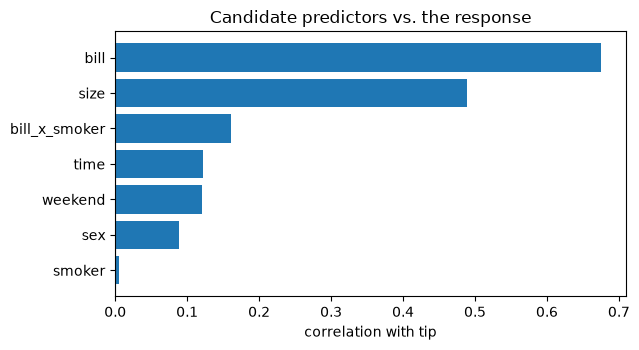

In [2]:
pool = pd.DataFrame(cand)
pool.insert(0, 'tip', Y)
r_tip = pool.corr()['tip'].drop('tip').sort_values(ascending=False)
print('correlation with tip:'); print(r_tip.round(3).to_string())
cm = pool[names].corr()
off = cm.where(~np.eye(k, dtype=bool)).abs().stack().sort_values(ascending=False)
print('\nlargest correlations among the predictors:')
for (a, b_), v in off.iloc[::2][:4].items(): print(f'  {a:<14}{b_:<14}{cm.loc[a, b_]:+.3f}')

plt.figure(figsize=(6.5, 3.6))
plt.barh(r_tip.index[::-1], r_tip.values[::-1])
plt.axvline(0, c='gray', lw=.8)
plt.xlabel('correlation with tip'); plt.title('Candidate predictors vs. the response')
plt.tight_layout()
plt.savefig('images/corr_with_tip.png')
plt.show()

## Six selection criteria

For a model with $p$ parameters (L6.1, slide 11):

| criterion | formula | choose |
|---|---|---|
| $R^2_p$ | $1-SSE_p/SSTO$ | large, but always increases |
| $R^2_{a,p}$ | $1-\dfrac{SSE_p/(n-p)}{SSTO/(n-1)}$ | maximize |
| $C_p$ | $\dfrac{SSE_p}{MSE(\text{full})}-(n-2p)$ | small, and $C_p\approx p$ |
| $AIC_p$ | $n\ln SSE_p-n\ln n+2p$ | minimize |
| $SBC_p$ | $n\ln SSE_p-n\ln n+p\ln n$ | minimize |
| $PRESS_p$ | $\sum_i\big(Y_i-\hat Y_{i(i)}\big)^2=\sum_i\big(e_i/(1-h_{ii})\big)^2$ | minimize |

Only **differences** of $AIC$ and $SBC$ between models matter: software (e.g. `statsmodels`) adds a different constant.

In [3]:
records = []
for r in range(k + 1):
    for sub in itertools.combinations(names, r):
        sse, p, press = fit_stats(sub)
        records.append(dict(sub=sub, p=p, SSE=sse, PRESS=press))
tab = pd.DataFrame(records)
sse_full = tab.loc[tab['p'] == k + 1, 'SSE'].iloc[0]
MSE_full = sse_full / (n - (k + 1))
tab['R2'] = 1 - tab['SSE'] / SSTO
tab['R2a'] = 1 - (tab['SSE'] / (n - tab['p'])) / (SSTO / (n - 1))
tab['Cp'] = tab['SSE'] / MSE_full - (n - 2 * tab['p'])
tab['AIC'] = n * np.log(tab['SSE']) - n * np.log(n) + 2 * tab['p']
tab['SBC'] = n * np.log(tab['SSE']) - n * np.log(n) + tab['p'] * np.log(n)
tab['label'] = tab['sub'].apply(lambda s: '+'.join(s) if s else '(intercept only)')

# checks: full model has Cp = p exactly; PRESS equals an explicit leave-one-out loop; R2a and AIC agree with statsmodels
assert np.isclose(tab.loc[tab['p'] == k + 1, 'Cp'].iloc[0], k + 1)
sub_chk = ('bill', 'smoker', 'bill_x_smoker')
Xc = design(sub_chk)
loo = np.empty(n)
for i in range(n):
    m_ = np.ones(n, bool); m_[i] = False
    bi = np.linalg.lstsq(Xc[m_], Y[m_], rcond=None)[0]
    loo[i] = Y[i] - Xc[i] @ bi
row = tab[tab['sub'] == sub_chk].iloc[0]
assert np.isclose((loo**2).sum(), row['PRESS']), 'PRESS via hat matrix disagrees with the explicit loop'
fits = {s: sm.OLS(Y, design(s)).fit() for s in tab['sub']}
assert np.allclose([fits[s].rsquared_adj for s in tab['sub']], tab['R2a'])
const = np.array([fits[s].aic for s in tab['sub']]) - tab['AIC'].to_numpy()
assert np.allclose(const, const[0]), 'AIC differs by more than a constant'
print(f'{len(tab)} models scored.  Checks passed: Cp(full) = p, PRESS = explicit leave-one-out, R2_a = statsmodels.')
print(f'statsmodels AIC - lecture AIC = {const[0]:.4f} for every model (so only differences matter).')
print(f'MSE(full) = {MSE_full:.4f} (df = {n - (k + 1)})')

128 models scored.  Checks passed: Cp(full) = p, PRESS = explicit leave-one-out, R2_a = statsmodels.
statsmodels AIC - lecture AIC = 692.4420 for every model (so only differences matter).
MSE(full) = 0.9698 (df = 236)


## Best subsets: the best model of each size

All $2^7$ models are scored, so the optimum for every criterion is certain (L6.1, slide 20).

In [4]:
best = tab.loc[tab.groupby('p')['SSE'].idxmin()].sort_values('p')
pd.set_option('display.width', 200)
print(f'{"p":>2}  {"best subset":<58}{"R2":>7}{"R2a":>8}{"Cp":>8}{"AIC":>8}{"SBC":>8}{"PRESS":>9}')
for _, r_ in best.iterrows():
    print(f'{r_["p"]:>2}  {r_["label"]:<58}{r_["R2"]:>7.4f}{r_["R2a"]:>8.4f}{r_["Cp"]:>8.2f}{r_["AIC"]:>8.1f}{r_["SBC"]:>8.1f}{r_["PRESS"]:>9.2f}')

print('\noptimum over all 128 models:')
for crit, asc in [('R2a', False), ('Cp', True), ('AIC', True), ('SBC', True), ('PRESS', True)]:
    r_ = tab.sort_values(crit, ascending=asc).iloc[0]
    print(f'  {crit:<6} {r_["label"]:<46} p = {r_["p"]}   {crit} = {r_[crit]:.4f}')

 p  best subset                                                    R2     R2a      Cp     AIC     SBC    PRESS
 1  (intercept only)                                           0.0000  0.0000  237.70   159.5   163.0   469.05
 2  bill                                                       0.4566  0.4544   20.66    12.6    19.6   260.49
 3  bill+bill_x_smoker                                         0.4754  0.4710   13.65     6.0    16.5   255.56
 4  bill+smoker+bill_x_smoker                                  0.5060  0.4998    0.97    -6.6     7.4   245.68
 5  bill+size+smoker+bill_x_smoker                             0.5080  0.4998    2.01    -5.6    11.9   247.98
 6  bill+size+smoker+weekend+bill_x_smoker                     0.5080  0.4977    4.00    -3.6    17.4   249.38
 7  bill+size+smoker+time+weekend+bill_x_smoker                0.5080  0.4956    6.00    -1.6    22.9   250.50
 8  bill+size+smoker+sex+time+weekend+bill_x_smoker            0.5080  0.4934    8.00     0.4    28.4   252.27



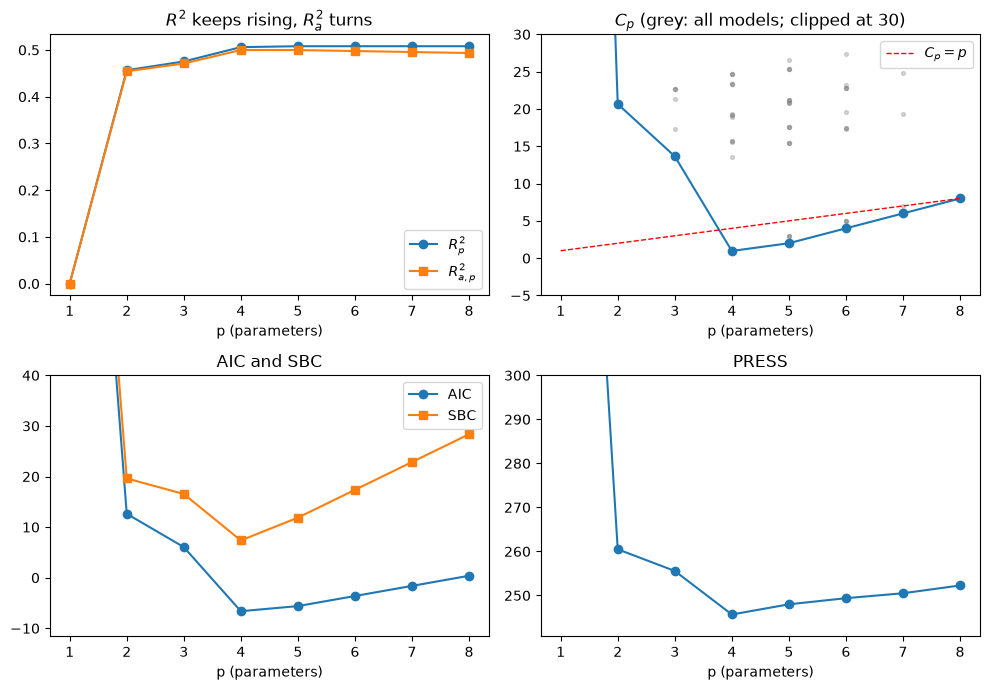

five best models by AIC (differences are what count):
model                                               p   dAIC   dSBC     R2a     Cp
bill+smoker+bill_x_smoker                           4   0.00   0.00  0.4998   0.97
bill+size+smoker+bill_x_smoker                      5   1.01   4.51  0.4998   2.01
bill+smoker+time+bill_x_smoker                      5   2.00   5.50  0.4977   2.97
bill+smoker+weekend+bill_x_smoker                   5   2.00   5.50  0.4977   2.97
bill+smoker+sex+bill_x_smoker                       5   2.00   5.50  0.4977   2.97


In [5]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
pp = best['p'].to_numpy()
ax[0, 0].plot(pp, best['R2'], 'o-', label='$R^2_p$'); ax[0, 0].plot(pp, best['R2a'], 's-', label='$R^2_{a,p}$')
ax[0, 0].set_title('$R^2$ keeps rising, $R^2_a$ turns'); ax[0, 0].legend()
ax[0, 1].scatter(tab['p'], tab['Cp'], s=8, alpha=.3, color='gray')
ax[0, 1].plot(pp, best['Cp'], 'o-'); ax[0, 1].plot([1, k + 1], [1, k + 1], 'r--', lw=1, label='$C_p=p$')
ax[0, 1].set_ylim(-5, 30); ax[0, 1].set_title('$C_p$ (grey: all models; clipped at 30)'); ax[0, 1].legend()
ax[1, 0].plot(pp, best['AIC'], 'o-', label='AIC'); ax[1, 0].plot(pp, best['SBC'], 's-', label='SBC')
ax[1, 0].set_ylim(best['AIC'].min() - 5, 40); ax[1, 0].set_title('AIC and SBC'); ax[1, 0].legend()
ax[1, 1].plot(pp, best['PRESS'], 'o-'); ax[1, 1].set_ylim(best['PRESS'].min() - 5, 300); ax[1, 1].set_title('PRESS')
for a in ax.ravel(): a.set_xlabel('p (parameters)'); a.set_xticks(pp)
plt.tight_layout()
plt.savefig('images/criteria_by_size.png')
plt.show()

top = tab.sort_values('AIC').head(5)
print('five best models by AIC (differences are what count):')
print(f'{"model":<50}{"p":>3}{"dAIC":>7}{"dSBC":>7}{"R2a":>8}{"Cp":>7}')
for _, r_ in top.iterrows():
    print(f'{r_["label"]:<50}{r_["p"]:>3}{r_["AIC"] - top["AIC"].iloc[0]:>7.2f}{r_["SBC"] - tab["SBC"].min():>7.2f}{r_["R2a"]:>8.4f}{r_["Cp"]:>7.2f}')

## Stepwise regression

One predictor is added or dropped at a time by a partial $F$ test on its extra sum of squares (L6.1, slides 21–22):

- **forward selection:** enter the largest partial $F$ if $P<\alpha_{enter}$; once in, never out;
- **backward elimination:** start full, drop the smallest partial $F$ if $P>\alpha_{remove}$; once out, never back;
- **forward stepwise:** forward selection, but after each entry re-test every term already in and drop any with $P>\alpha_{stay}$.

Thresholds $\alpha_{enter}=0.05\le\alpha_{stay}=\alpha_{remove}=0.10$. Each follows one path and the $P$ values are optimistic.

In [6]:
A_ENTER, A_STAY = 0.05, 0.10
SSE_of = {frozenset(s): v for s, v in zip(tab['sub'], tab['SSE'])}
def key(S): return tuple(x for x in names if x in S)

def p_to_enter(S, v):                      # partial F for adding v to the model S
    s1 = SSE_of[frozenset(S | {v})]; df2 = n - (len(S) + 2)
    F = (SSE_of[frozenset(S)] - s1) / (s1 / df2)
    return F, stats.f.sf(F, 1, df2)

def p_to_remove(S, v):                     # partial F for dropping v from the model S
    s_full = SSE_of[frozenset(S)]; df2 = n - (len(S) + 1)
    F = (SSE_of[frozenset(S - {v})] - s_full) / (s_full / df2)
    return F, stats.f.sf(F, 1, df2)

def forward(stepwise):
    S, log = set(), []
    while True:
        out = [v for v in names if v not in S]
        if not out: break
        cands = {v: p_to_enter(S, v) for v in out}
        v = max(cands, key=lambda c: cands[c][0])
        if cands[v][1] >= A_ENTER:
            log.append(f'stop: best candidate {v} has P = {cands[v][1]:.3f}'); break
        S.add(v); log.append(f'enter {v:<14} F = {cands[v][0]:8.2f}  P = {cands[v][1]:.2e}')
        while stepwise and len(S) > 1:
            rem = {u: p_to_remove(S, u) for u in S if u != v}
            if not rem: break
            u = min(rem, key=lambda c: rem[c][0])
            if rem[u][1] > A_STAY:
                S.remove(u); log.append(f'drop  {u:<14} F = {rem[u][0]:8.2f}  P = {rem[u][1]:.3f}   (re-test)')
            else: break
    return S, log

def backward():
    S, log = set(names), []
    while S:
        rem = {u: p_to_remove(S, u) for u in S}
        u = min(rem, key=lambda c: rem[c][0])
        if rem[u][1] <= A_STAY:
            log.append(f'stop: smallest F is {u} with P = {rem[u][1]:.2e}'); break
        S.remove(u); log.append(f'drop  {u:<14} F = {rem[u][0]:8.2f}  P = {rem[u][1]:.3f}')
    return S, log

paths = {'forward selection': forward(False), 'backward elimination': backward(), 'forward stepwise': forward(True)}
chosen = {}
for nm_, (S, log) in paths.items():
    print(f'--- {nm_}')
    for l in log: print('   ', l)
    chosen[nm_] = key(S)
    print(f'   result: {{{", ".join(key(S))}}}\n')

opt = tab.sort_values('AIC').iloc[0]['sub']
print('best subsets (min AIC, SBC, PRESS, Cp, max R2a all agree):', opt)
for nm_, s in chosen.items(): print(f'  {nm_:<22} {"same as best subsets" if s == opt else "DIFFERENT"}')

--- forward selection
    enter bill           F =   203.36  P = 6.69e-34
    enter bill_x_smoker  F =     8.63  P = 3.63e-03
    enter smoker         F =    14.87  P = 1.48e-04
    stop: best candidate size has P = 0.325
   result: {bill, smoker, bill_x_smoker}

--- backward elimination
    drop  sex            F =     0.00  P = 0.996
    drop  time           F =     0.00  P = 0.966
    drop  weekend        F =     0.00  P = 0.950
    drop  size           F =     0.97  P = 0.325
    stop: smallest F is smoker with P = 1.48e-04
   result: {bill, smoker, bill_x_smoker}

--- forward stepwise
    enter bill           F =   203.36  P = 6.69e-34
    enter bill_x_smoker  F =     8.63  P = 3.63e-03
    enter smoker         F =    14.87  P = 1.48e-04
    stop: best candidate size has P = 0.325
   result: {bill, smoker, bill_x_smoker}

best subsets (min AIC, SBC, PRESS, Cp, max R2a all agree): ('bill', 'smoker', 'bill_x_smoker')
  forward selection      same as best subsets
  backward eliminati

## Validation: data splitting and the MSPR

The chosen model was optimised on this sample, so its in-sample fit is optimistic. Split the cases into a training set and a
validation set, fit on the training set, and compare

$$MSPR=\frac{\sum_{i=1}^{n^*}(Y_i-\hat Y_i)^2}{n^*}\qquad\text{with}\qquad MSE_{train}$$

(L6.1, slide 25). $MSPR\approx MSE$ means the model validates; $MSPR\gg MSE$ means overfitting. $PRESS_p/n$ is the leave-one-out proxy.

one random split: 122 training / 122 validation cases

model                                       MSE train     MSPR  MSPR/MSE   PRESS/n
bill only                                      0.8827   1.2169     1.379    1.0676
selected (bill, smoker, bill x smoker)         0.8302   1.1255     1.356    1.0069
all 7 predictors                               0.8318   1.1855     1.425    1.0339



1000 random 50/50 splits:
model                                       mean MSPR      sd  mean MSPR/MSE
bill only                                      1.0838  0.1424          1.082
selected (bill, smoker, bill x smoker)         1.0338  0.1578          1.150
all 7 predictors                               1.0796  0.1651          1.187

share of splits in which each model has the smallest MSPR: {'bill only': np.float64(0.216), 'selected (bill, smoker, bill x smoker)': np.float64(0.766), 'all 7 predictors': np.float64(0.018)}


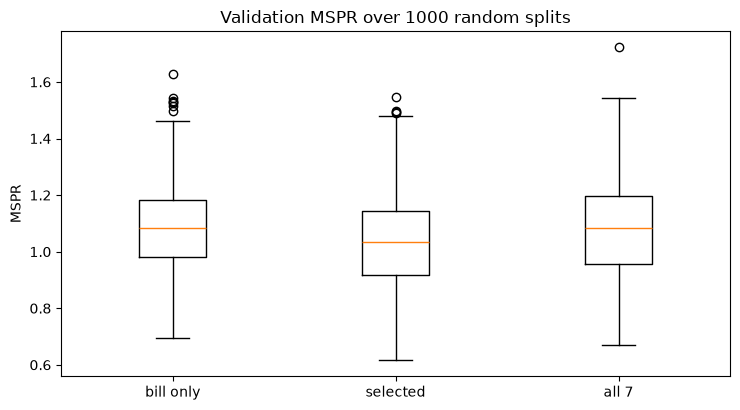

In [7]:
models_v = {'bill only': ('bill',),
            'selected (bill, smoker, bill x smoker)': opt,
            'all 7 predictors': tuple(names)}

def split_scores(sub, tr, va):
    Xt, Xv = design(sub)[tr], design(sub)[va]
    b = np.linalg.lstsq(Xt, Y[tr], rcond=None)[0]
    mse_tr = ((Y[tr] - Xt @ b)**2).sum() / (len(tr) - Xt.shape[1])
    return mse_tr, ((Y[va] - Xv @ b)**2).mean()

rng = np.random.default_rng(2026)
perm = rng.permutation(n)
tr, va = np.sort(perm[:n // 2]), np.sort(perm[n // 2:])
print(f'one random split: {len(tr)} training / {len(va)} validation cases\n')
print(f'{"model":<42}{"MSE train":>11}{"MSPR":>9}{"MSPR/MSE":>10}{"PRESS/n":>10}')
for nm_, s in models_v.items():
    m_tr, mspr = split_scores(s, tr, va)
    print(f'{nm_:<42}{m_tr:>11.4f}{mspr:>9.4f}{mspr / m_tr:>10.3f}{fit_stats(s)[2] / n:>10.4f}')

R = 1000
res = {nm_: np.empty(R) for nm_ in models_v}
ratio = {nm_: np.empty(R) for nm_ in models_v}
for r_ in range(R):
    pm = rng.permutation(n); t_, v_ = pm[:n // 2], pm[n // 2:]
    for nm_, s in models_v.items():
        m_tr, mspr = split_scores(s, t_, v_); res[nm_][r_] = mspr; ratio[nm_][r_] = mspr / m_tr
print(f'\n{R} random 50/50 splits:')
print(f'{"model":<42}{"mean MSPR":>11}{"sd":>8}{"mean MSPR/MSE":>15}')
for nm_ in models_v: print(f'{nm_:<42}{res[nm_].mean():>11.4f}{res[nm_].std(ddof=1):>8.4f}{ratio[nm_].mean():>15.3f}')
mat = np.column_stack([res[m_] for m_ in models_v])
win = np.bincount(mat.argmin(axis=1), minlength=3) / R
print('\nshare of splits in which each model has the smallest MSPR:', {m_: round(w, 3) for m_, w in zip(models_v, win)})

plt.figure(figsize=(7.5, 4.2))
plt.boxplot([res[m_] for m_ in models_v], tick_labels=['bill only', 'selected', 'all 7'])
plt.ylabel('MSPR'); plt.title(f'Validation MSPR over {R} random splits')
plt.tight_layout()
plt.savefig('images/mspr_splits.png')
plt.show()

## The selected model

$$\hat Y=b_0+b_1\,bill+b_2\,smoker+b_3\,bill\times smoker$$

This is the week-5 smoker/non-smoker pair of lines. Selection treats the interaction as one more candidate and keeps it together with its two main effects.

In [8]:
Xs = design(opt)
fs = sm.OLS(Y, Xs).fit()
print(f'{"":<16}{"b":>9}{"s{b}":>9}{"t*":>8}{"P":>11}')
for nm_, b_, s_, t_, p_ in zip(['intercept'] + list(opt), fs.params, fs.bse, fs.tvalues, fs.pvalues):
    print(f'{nm_:<16}{b_:>9.4f}{s_:>9.4f}{t_:>+8.2f}{p_:>11.3g}')
print(f'\nR2 = {fs.rsquared:.4f}, R2_a = {fs.rsquared_adj:.4f}, MSE = {fs.mse_resid:.4f}')
print(f'slope of the bill: non-smokers {fs.params[1]:.4f}, smokers {fs.params[1] + fs.params[3]:.4f}')

# the selection did not fix the residual behaviour found in weeks 3-5
e_s = fs.resid
w_ = e_s**2
bw = np.linalg.lstsq(Xs, w_, rcond=None)[0]
chi2 = ((Xs @ bw - w_.mean())**2).sum() / 2 / ((e_s @ e_s) / n)**2
print(f'\nBreusch-Pagan: X2 = {chi2:.2f} on {Xs.shape[1] - 1} df, P = {stats.chi2.sf(chi2, Xs.shape[1] - 1):.3g}')
print(f'normal probability plot correlation r = {np.corrcoef(np.sort(e_s), stats.norm.ppf((np.arange(1, n + 1) - .375) / (n + .25)))[0, 1]:.4f}')

                        b     s{b}      t*          P
intercept          0.3601   0.2021   +1.78      0.076
bill               0.1372   0.0097  +14.17   1.55e-33
smoker             1.2042   0.3123   +3.86   0.000148
bill_x_smoker     -0.0676   0.0142   -4.76   3.32e-06

R2 = 0.5060, R2_a = 0.4998, MSE = 0.9575
slope of the bill: non-smokers 0.1372, smokers 0.0696

Breusch-Pagan: X2 = 102.64 on 3 df, P = 4.21e-22
normal probability plot correlation r = 0.9754


## Summary

- Over all 128 subsets, $R^2_a$, $C_p$ ($0.97$, near $p=4$), $AIC$, $SBC$ and $PRESS$ **all** pick `bill + smoker + bill_x_smoker`.
- Adding `size` costs $\Delta AIC=+1.0$ and $\Delta SBC=+4.5$ with no gain in $R^2_a$: a near tie that SBC separates.
- Forward selection, backward elimination and forward stepwise all end at the same model.
- On 1000 random 50/50 splits the selected model has the lowest mean MSPR ($1.034$ vs $1.084$ for the bill alone and $1.080$ for all seven)
  and the lowest MSPR in $77\%$ of splits.
- The selected model is the week-5 pair of lines (slopes $0.137$ and $0.070$). It still fails constant variance and normality.
